(z3-number-link)=
# 数回：用一条线把相同的两个数字连接起来

## 这一章讲什么

[数回](https://en.wikipedia.org/wiki/Numberlink)的玩法很简单：写着同一个数字的两格，用一条线连起来，线只走上下左右。这一章把这个游戏翻译成 Z3 的约束，下面先列出要点，再逐条说明其写法。

- 变量有两样：格子的值，以及“相邻两格之间那条线在不在”
- 数字格有 1 条线，空白格有 2 条(“正好 n 条”交给 `PbEq`)
- 由线连接起来的两格，其值必须相等

有两处值得留意：`PbEq()` 所说的“正好 n 个”，以及用 `defaultdict` 搭起来的“格子→线”对应表，注意后者省去了大量重复的变量。

## 规则

盘面

- 一块方格棋盘。
- 有些格子里印着数字。
- 大小不限，10×10 最常见。

目标

- 把写着同一个数字的两格用线连上。
- 数字对全部连完，就算通关。

线的规则

- 线只走上下左右，不能斜着走。
- 线不能交叉，也不能分叉。

通关条件

- 每一对数字都连上了
- 线不交叉、不分叉
- 每条线从头到尾连着，中间没有断开

![](https://upload.wikimedia.org/wikipedia/commons/e/e0/Numberlink_puzzle_solution.svg?utm_source=commons.wikimedia.org&utm_campaign=index&utm_content=original)

:::{seealso}
[用 OrTools 解数回谜题](ortools-number-link)
:::

`````{admonition} 数回谜题网站
:class: tip
https://puzzlemadness.co.uk/numberlink/medium

用 `helper.puzzle.extract_number_link()` 就能从这个网站取得盘面。打开浏览器的源码，找到 `puzzledata` 那一行，把里面的 JSON 数据抄出来传给这个函数，它就返回一个数组形式的盘面，其中每个元素代表一个格子。
`````

## 盘面的表示方法

盘面就是一个二维数组，其中每个元素对应一个格子，行列下标与格子的位置一一对应。

- `0` 是空格子，不属于任何数字
- `1` 以上就是需要配对的数字，同一个数字的两格要用线连起来

这一章使用的盘面放在 `data/` 下的文本文件里，读进来就是这样一个数组，因此不必另外定义格式。

In [1]:
import numpy as np

board = np.loadtxt('data/numberlink01.txt', dtype=np.uint8)
print(board)

[[1 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 5 0]
 [0 6 0 1 0 0 0 0 0 0]
 [0 0 0 0 0 4 3 0 0 0]
 [0 0 0 0 0 0 6 0 5 0]
 [0 8 0 3 0 0 0 0 0 0]
 [0 0 0 4 7 0 0 0 0 0]
 [0 0 0 0 0 0 2 0 8 0]
 [0 7 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 2]]


## 画出盘面

`plot_number_link_board()` 把盘面与解答一起画出来。`links` 是一个 `(r1, c1, r2, c2) → Bool` 的字典，其中哪一项取 `True`，就说明格子 `(r1, c1)` 与 `(r2, c2)` 之间有连线。`values` 给出每个格子的值，下面看线的颜色如何确定：由于线代表的数字由两端决定，因此颜色就按这个值来定，例如数字 1 的线用一种颜色，数字 2 的线用另一种。

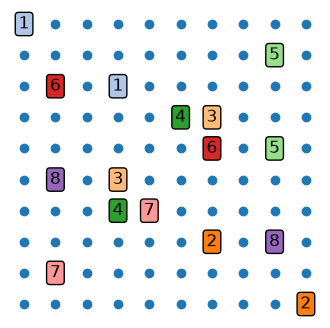

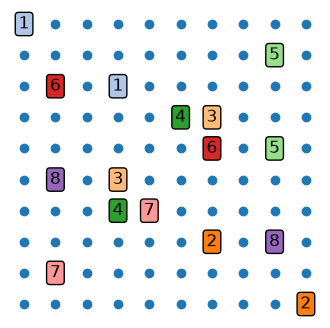

In [2]:
from matplotlib import pyplot as plt
from matplotlib.cm import tab20
from z3 import is_true


def plot_number_link_board(board, links=None, values=None):
    """画出盘面。传入 links 和 values 时，也画出解出来的线"""
    h, w = board.shape
    fig, ax = plt.subplots(1, 1, figsize=(w * 0.4, h * 0.4))

    # 画线（颜色由格子的值决定）
    if links is not None and values is not None:
        for (r1, c1, r2, c2), link in links.items():
            if is_true(link):
                ax.plot([c1, c2], [r1, r2], color=tab20.colors[values[r1, c1]], lw=3)

    # 画数字格
    xs, ys, texts = [], [], []
    for (r, c), v in np.ndenumerate(board):
        xs.append(c)
        ys.append(r)
        texts.append(str(v))

    ax.scatter(xs, ys)
    for x, y, s in zip(xs, ys, texts):
        if s != "0":
            ax.text(x, y, s, ha='center', va='center', fontsize=12,
                    bbox=dict(facecolor=tab20.colors[int(s)], edgecolor='black',
                              boxstyle='round,pad=0.2'))

    ax.invert_yaxis()
    ax.axis('off')
    return fig


plot_number_link_board(board)

## 解法

变量只有两类，分别表示格子的值与相邻两格之间的线是否存在，两者的数量都很有限，足以描述整个盘面的全部信息。

- `value[r, c]` … 格子 `(r, c)` 的值(`Int`)
- `link[r, c, r2, c2]` … 相邻两格之间有没有线(`Bool`)

线不必四个方向都建，只往“右”和“下”两个方向生长即可：左边和上边那条线，换到相邻的格子去看，正是它的右和下。

约束有五条，其中前两条限定取值范围，后三条描述线如何连接。

1. 每个格子的值都落在 0〜最大值之间
2. 印着数字的格子，值不能改动
3. 数字格连出去的线正好 1 条，它就是线的端点
4. 空白格连着的线正好 2 条，线从这里穿过
5. 一条线连着的两格，值相等

第 3、4 条一上，线就既分不了叉，也断不了。由于值相等这件事会沿着线一路传下去，因此同一个数字自然就接上了。这样，整条线从一端的数字通到另一端，中间不会出现断口。

这段代码解的是空白格也一定有线穿过、把盘面填满的那一版。

In [3]:
from z3 import *
from collections import defaultdict


def solve_number_link(board):
    """解出盘面，返回 (links, values)"""
    h, w = board.shape
    max_value = int(board.max())

    # 每个格子的值
    value = {(r, c): Int(f'C_{r}_{c}') for r, c in np.ndindex(h, w)}

    # 相邻格子之间的线（只生成右和下）
    link = {}
    cell_links = defaultdict(list)      # 格子 → 连到这个格子的线
    for r, c in np.ndindex(h, w):
        for r2, c2 in ((r, c + 1), (r + 1, c)):
            if r2 < h and c2 < w:
                b = Bool(f'L_{r}_{c}_{r2}_{c2}')
                link[r, c, r2, c2] = b
                cell_links[r, c].append(b)
                cell_links[r2, c2].append(b)

    solver = Solver()

    # 1. 值的范围
    for v in value.values():
        solver.add(0 <= v, v <= max_value)

    for (r, c), v in np.ndenumerate(board):
        if v > 0:
            solver.add(value[r, c] == int(v))                          # 2. 数字保持不变
            solver.add(PbEq([(b, 1) for b in cell_links[r, c]], 1))    # 3. 端点有 1 条线
        else:
            solver.add(PbEq([(b, 1) for b in cell_links[r, c]], 2))    # 4. 通道有 2 条线

    # 5. 用线连起来的格子值相等
    for (r, c, r2, c2), b in link.items():
        solver.add(Implies(b, value[r, c] == value[r2, c2]))

    if solver.check() != sat:
        raise ValueError("没有找到解")

    m = solver.model()
    solved_links = {key: m.eval(b, model_completion=True) for key, b in link.items()}
    solved_values = {key: m.eval(v, model_completion=True).as_long() for key, v in value.items()}
    return solved_links, solved_values

## 执行示例

说解就解，下面把线画出来。

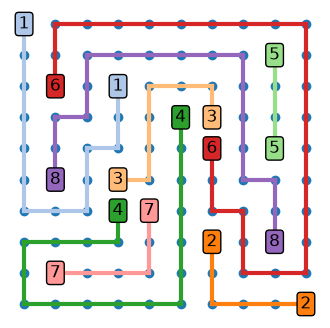

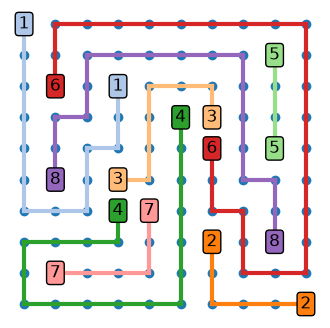

In [4]:
links, values = solve_number_link(board)
plot_number_link_board(board, links, values)

## 换一个大一点的盘面

格子一多，线的组合也跟着增加，可 Z3 用的还是同一段代码。

CPU times: total: 1.28 s
Wall time: 1.3 s


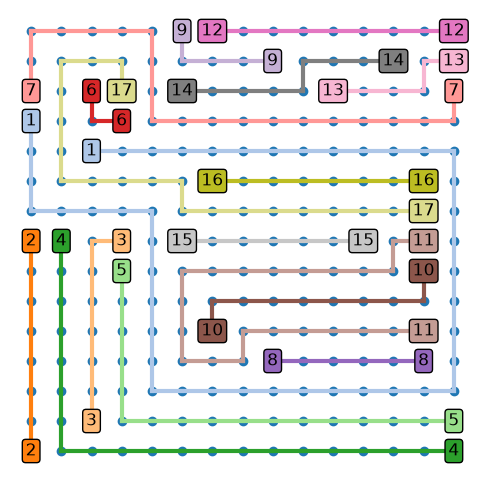

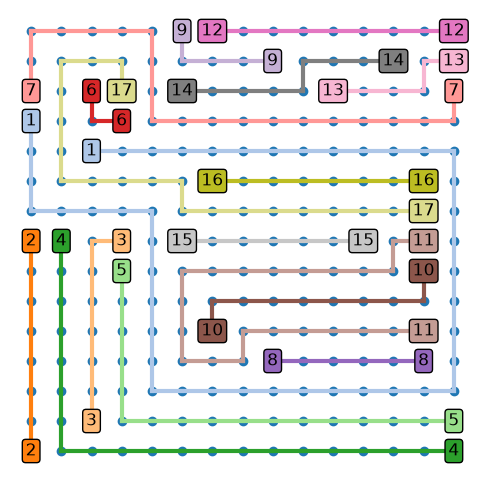

In [5]:
%%time
board = np.loadtxt('data/numberlink02.txt', dtype=np.uint8)
links, values = solve_number_link(board)
plot_number_link_board(board, links, values)

## 小结

- 变量只有两类：格子的值(`Int`)，以及相邻两格之间的线(`Bool`)
- “正好 1 条”“正好 2 条”，都可以用 `PbEq([...], n)` 写出来
- 让连起来的两格值相等，同一个数字自然就接通了
- 线只建右和下两个方向即可，重复的变量一个也不必建
- 这段代码是“所有格子都有线穿过”的版本。要像一般数回那样留出空格，把空白格的约束改成 `Or(PbEq(..., 0), PbEq(..., 2))` 即可